In [2]:
import os
import sys
import numpy as np
import pandas as pd
sys.path.append("../utils")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# clean text data
import re
# import string
# from nltk.corpus import stopwords
# from nltk.stem import WordNetLemmatizer
# import nltk 

import spacy
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from wordcloud import WordCloud

# nltk.download("stopwords")
# nltk.download("wordnet")
# nltk.download("omw-1.4")


# text embeddings
from transformers import AutoTokenizer, AutoModel
from embedding_utils import extract_embeddings
from sentence_transformers import SentenceTransformer


# clustering
import hdbscan
from bertopic import BERTopic

# visualization
import matplotlib.pyplot as plt


In [3]:
df = pd.read_csv("../data/raw/corrected_data.csv")
df.head()

,bill_number,bill_url,bill_title,sponsor_name,sponsor_url,summary_title,summary_text,source_url,view_text_url,download_pdf_url,is_home_rule,municipality,num_cosponsors,cosponsors,history,path,summary_title_clean,cleaned,community_id
0,H.4147,https://malegislature.gov/Bills/192/H4147,An Act providing technical education and econo...,"Harrington, Sheila C.",https://malegislature.gov/Legislators/Profile/...,An Act providing technical education and econo...,"(a) For purposes of this act, “autism spectrum...",https://malegislature.gov/Bills/192/H4147,https://malegislature.gov/Bills/192/H4147/Hous...,https://malegislature.gov/Bills/192/H4147.pdf,False,NaN,3,"[{'name': 'Lindsay N. Sabadosa', 'district': '...","[{'date': '9/30/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...,An Act providing technical education and econo...,technical education economic opportunity citiz...,33.0
1,S.1263,https://malegislature.gov/Bills/192/S1263,An Act relative to recovery homes,"Collins, Nick",https://malegislature.gov/Legislators/Profile/...,An Act relative to recovery homes,Nothwithstanding any special or general law to...,https://malegislature.gov/Bills/192/S1263,https://malegislature.gov/Bills/192/S1263/Sena...,https://malegislature.gov/Bills/192/S1263.pdf,False,NaN,0,[],"[{'date': '3/29/2021', 'branch': 'Senate', 'ac...",../../downloaded_legislation/state/MA/192nd/20...,An Act relative to recovery homes,recovery home,1.0
2,H.3682,https://malegislature.gov/Bills/192/H3682,An Act amending the Medal of Liberty,"Murray, Brian W.",https://malegislature.gov/Legislators/Profile/...,An Act amending the Medal of Liberty,"Chapter 33 Section 67A of the General Laws, as...",https://malegislature.gov/Bills/192/H3682,https://malegislature.gov/Bills/192/H3682/Hous...,https://malegislature.gov/Bills/192/H3682.pdf,False,NaN,7,"[{'name': 'Michael J. Soter', 'district': '8th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...,An Act amending the Medal of Liberty,medal liberty,27.0
3,SD.3464,https://malegislature.gov/Bills/192/SD3464,DVS Veteran Advisory Committee Interim Report,Department of Veterans’ Services,NaN,DVS Veteran Advisory Committee Interim Report,Report of the Department of Veterans’ Services...,https://malegislature.gov/Bills/192/SD3464,NaN,https://malegislature.gov/Bills/192/SD3464.pdf,False,NaN,0,[],"[{'date': '1/3/2023', 'branch': 'Senate', 'act...",../../downloaded_legislation/state/MA/192nd/20...,DVS Veteran Advisory Committee Interim Report,dvs veteran advisory interim report,27.0
4,H.2990,https://malegislature.gov/Bills/192/H2990,An Act to encourage Massachusetts residency,"Livingstone, Jay D.",https://malegislature.gov/Legislators/Profile/...,An Act to encourage Massachusetts residency,SECTION 1. Chapter 65C of the General Laws is ...,https://malegislature.gov/Bills/192/H2990,https://malegislature.gov/Bills/192/H2990/Hous...,https://malegislature.gov/Bills/192/H2990.pdf,False,NaN,1,"[{'name': 'Carlos González', 'district': '10th...","[{'date': '3/29/2021', 'branch': 'House', 'act...",../../downloaded_legislation/state/MA/192nd/20...,An Act to encourage Massachusetts residency,encourage residency,31.0


In [ ]:
# Load spaCy English model with NER and parser disabled for speed
nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])

custom_stopwords = set([
    "section", "chapter", "general", "laws", "hereby", "amended", "insert", "enact",
    "enactment", "law", "legislation", "act", "resolve", "order", "committee", "bill",
    "house", "senate", "commonwealth", "public", "private", "regulation", "statute",
    "effective", "provision", "subsection", "notwithstanding", "pursuant", "authorized",
    "office", "duty", "power", "authority", "text", "available", "clerk", "authorized",
    "recess", "investigation", "study", "authorized", "sitting", "office", "provide",
    "shall",  "state", "amend", "official", "edition", 
    "insert", "follow", "paragraph", "clause", "department", "relative",
    "massachusetts", "submit", "", "establish",
        "leave",     # very common, ambiguous
    "sick",      # procedural in employee/sick leave laws
    "employee",  # generic term across labor bills
    "fiscal",    # procedural, not topically defining
    "year",      # always present in budget/timing
    "commission",# too procedural, like “committee”
    "inspection",# structural
    "item",      # budget structure
    "county",    # geographical, not thematic
    "trust"      # legal term, often in estate/tax docs
])
stopwords = ENGLISH_STOP_WORDS.union(custom_stopwords)
# remove fire from stopwords
stopwords = set(stopwords)

# Now remove 'fire' safely
stopwords = stopwords.difference({"fire", "children", "study", "family", "order", "regulation"})

In [30]:
def preprocess(text):
    if pd.isnull(text):
        return np.nan
    doc = nlp(text.lower())
    tokens = [
        token.lemma_ for token in doc
        if token.is_alpha and not token.is_stop and token.lemma_ not in stopwords
    ]
    cleaned = " ".join(tokens)
    if cleaned == "":
        return np.nan
    return " ".join(tokens)


df["cleaned"] = df["bill_title"].apply(preprocess)

In [35]:
df.cleaned = df.cleaned.fillna('further amend or relative to other act')

In [36]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model.encode(df.cleaned.values, show_progress_bar=True)


Batches:   0%|          | 0/1135 [00:00<?, ?it/s]

In [37]:
import numpy as np
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
import community.community_louvain as community_louvain

# Compute cosine similarity matrix
cos_sim = cosine_similarity(embeddings)

# Use k nearest neighbors 
k = 20
G = nx.Graph()

for i in range(len(cos_sim)):
    top_k_idx = np.argsort(cos_sim[i])[::-1][1:k+1]  # skip self at [0]
    for j in top_k_idx:
        G.add_edge(i, j, weight=cos_sim[i][j])

partition = community_louvain.best_partition(G)

In [68]:
def get_partitions(embeddings=embeddings, k= 20):
    cos_sim = cosine_similarity(embeddings)
    G = nx.Graph()

    for i in range(len(cos_sim)):
        top_k_idx = np.argsort(cos_sim[i])[::-1][1:k+1]  # skip self at [0]
        for j in top_k_idx:
            G.add_edge(i, j, weight=cos_sim[i][j])

    partition = community_louvain.best_partition(G)
    return partition


In [ ]:
partitions = {}
for k in [20, 50, 100, 150, 300]:
    partition = get_partitions(k=k)
    partition_ids = [partition[i] for i in range(df.shape[0])]
    partitions[k] = {'number_of_partitions': len(set(partition_ids)),
                     'partitions': partition_ids}

In [90]:
import json

with open("partition.json", "w") as f:
    json.dump(partitions, f, indent=4)

In [101]:
partitions[100]

{'number_of_partitions': 20,
 'partitions': [0,
  4,
  9,
  9,
  3,
  2,
  9,
  14,
  4,
  8,
  9,
  17,
  11,
  2,
  1,
  5,
  12,
  9,
  0,
  6,
  14,
  1,
  4,
  19,
  19,
  18,
  4,
  2,
  14,
  3,
  18,
  7,
  12,
  6,
  12,
  8,
  16,
  9,
  13,
  9,
  7,
  14,
  8,
  2,
  3,
  14,
  15,
  18,
  14,
  17,
  6,
  17,
  6,
  3,
  18,
  17,
  14,
  15,
  8,
  8,
  16,
  18,
  17,
  9,
  17,
  3,
  19,
  12,
  9,
  1,
  3,
  15,
  3,
  6,
  8,
  6,
  14,
  1,
  7,
  9,
  3,
  6,
  17,
  7,
  1,
  15,
  3,
  6,
  2,
  1,
  4,
  15,
  12,
  14,
  7,
  9,
  12,
  6,
  9,
  5,
  8,
  10,
  3,
  16,
  8,
  3,
  8,
  18,
  4,
  14,
  1,
  3,
  14,
  5,
  8,
  10,
  2,
  15,
  4,
  14,
  7,
  2,
  6,
  1,
  12,
  2,
  16,
  13,
  3,
  3,
  14,
  1,
  12,
  18,
  7,
  16,
  19,
  3,
  3,
  12,
  10,
  3,
  14,
  3,
  18,
  9,
  9,
  7,
  15,
  7,
  11,
  19,
  2,
  9,
  1,
  13,
  2,
  3,
  6,
  1,
  7,
  8,
  3,
  14,
  6,
  3,
  4,
  0,
  1,
  10,
  1,
  11,
  9,
  14,
  5,
  18,
  19,
  1

In [102]:
df['community_id'] = [partitions[100]['partitions'][i] for i in range(df.shape[0])]

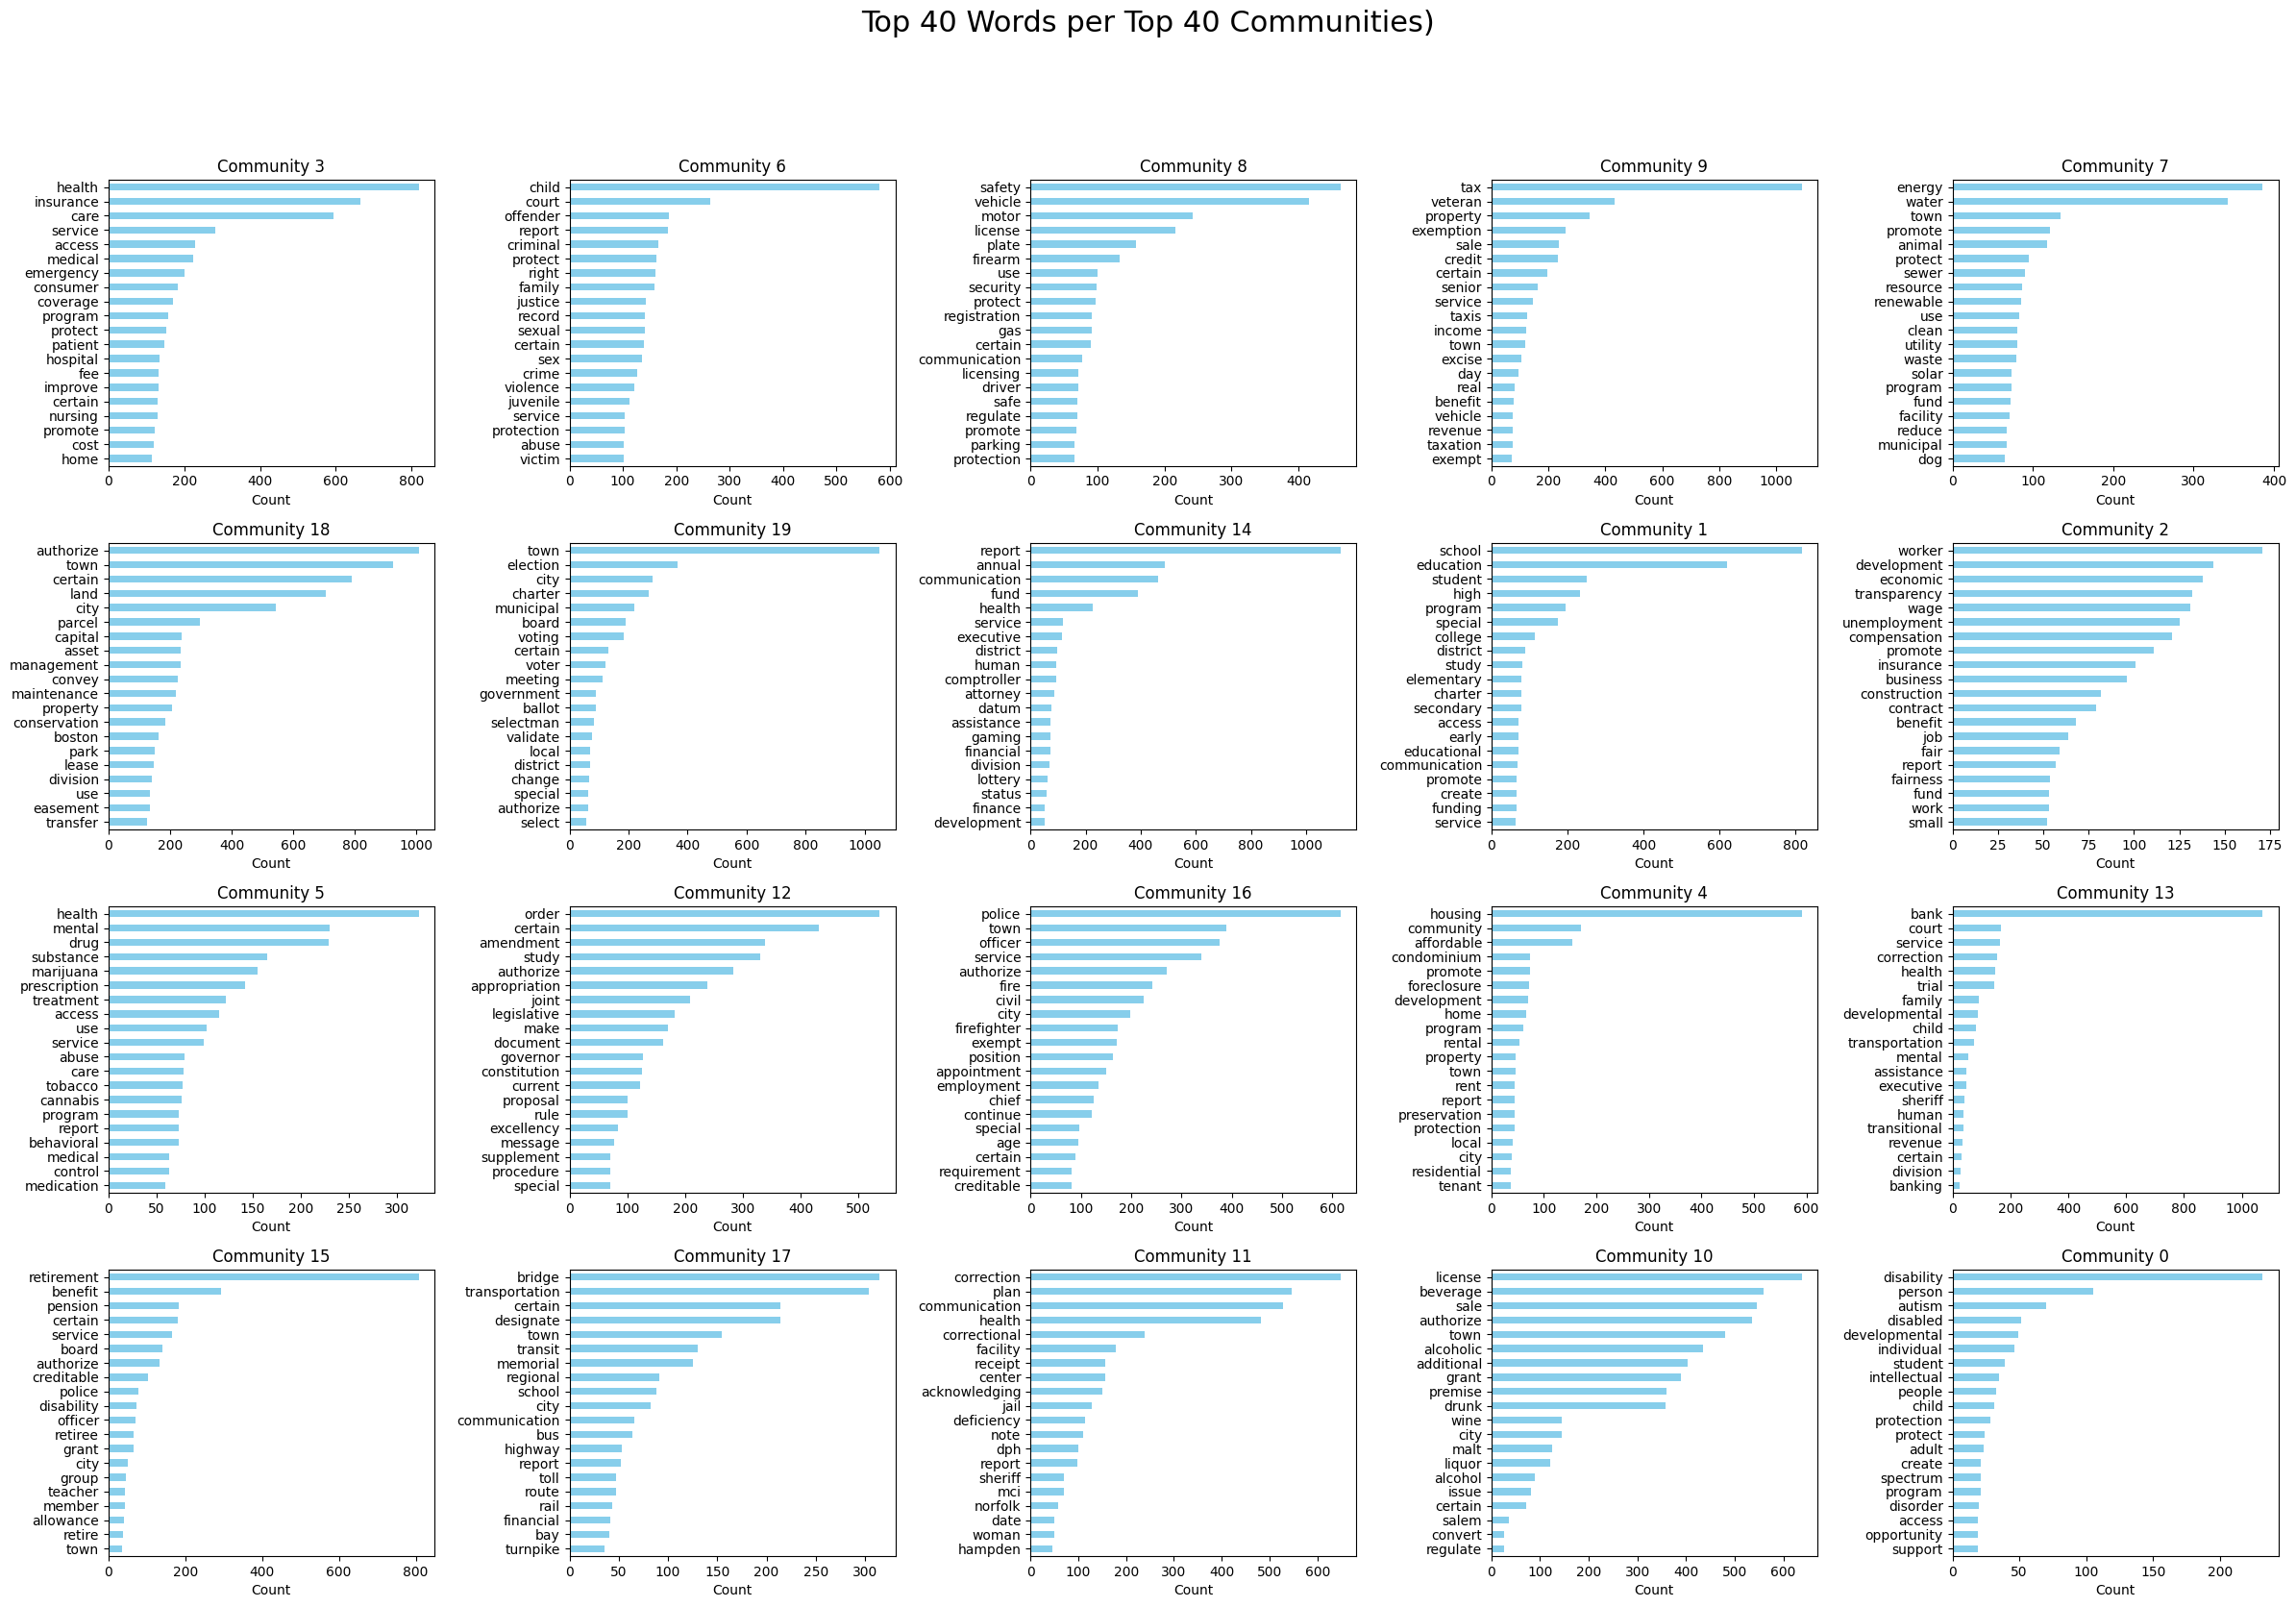

In [103]:
# Select the top 40 most populated communities
top_40_communities = df["community_id"].value_counts().nlargest(40).index.tolist()

# Set up 6x5 plot grid
n_cols = 5
n_rows = 8
fig, axes = plt.subplots(n_rows, n_cols, figsize=(24, n_rows * 4), sharey=False)
axes = axes.flatten()
fig.suptitle("Top 40 Words per Top 40 Communities)", fontsize=22)

# Plot top 40 words for each of the top 40 communities
for idx, comm_id in enumerate(top_40_communities):
    ax = axes[idx]
    words = ' '.join(df[df.community_id == comm_id].cleaned.values).split()
    top_words = pd.Series(words).value_counts().head(20)

    top_words.plot(kind='barh', ax=ax, color='skyblue')
    ax.set_title(f"Community {comm_id}", fontsize=12)
    ax.invert_yaxis()
    ax.set_xlabel("Count")
    ax.set_ylabel("")

# Remove any unused subplots
for j in range(len(top_40_communities), len(axes)):
    fig.delaxes(axes[j])

# figure size
plt.subplots_adjust(hspace=0.4, wspace=0.4)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


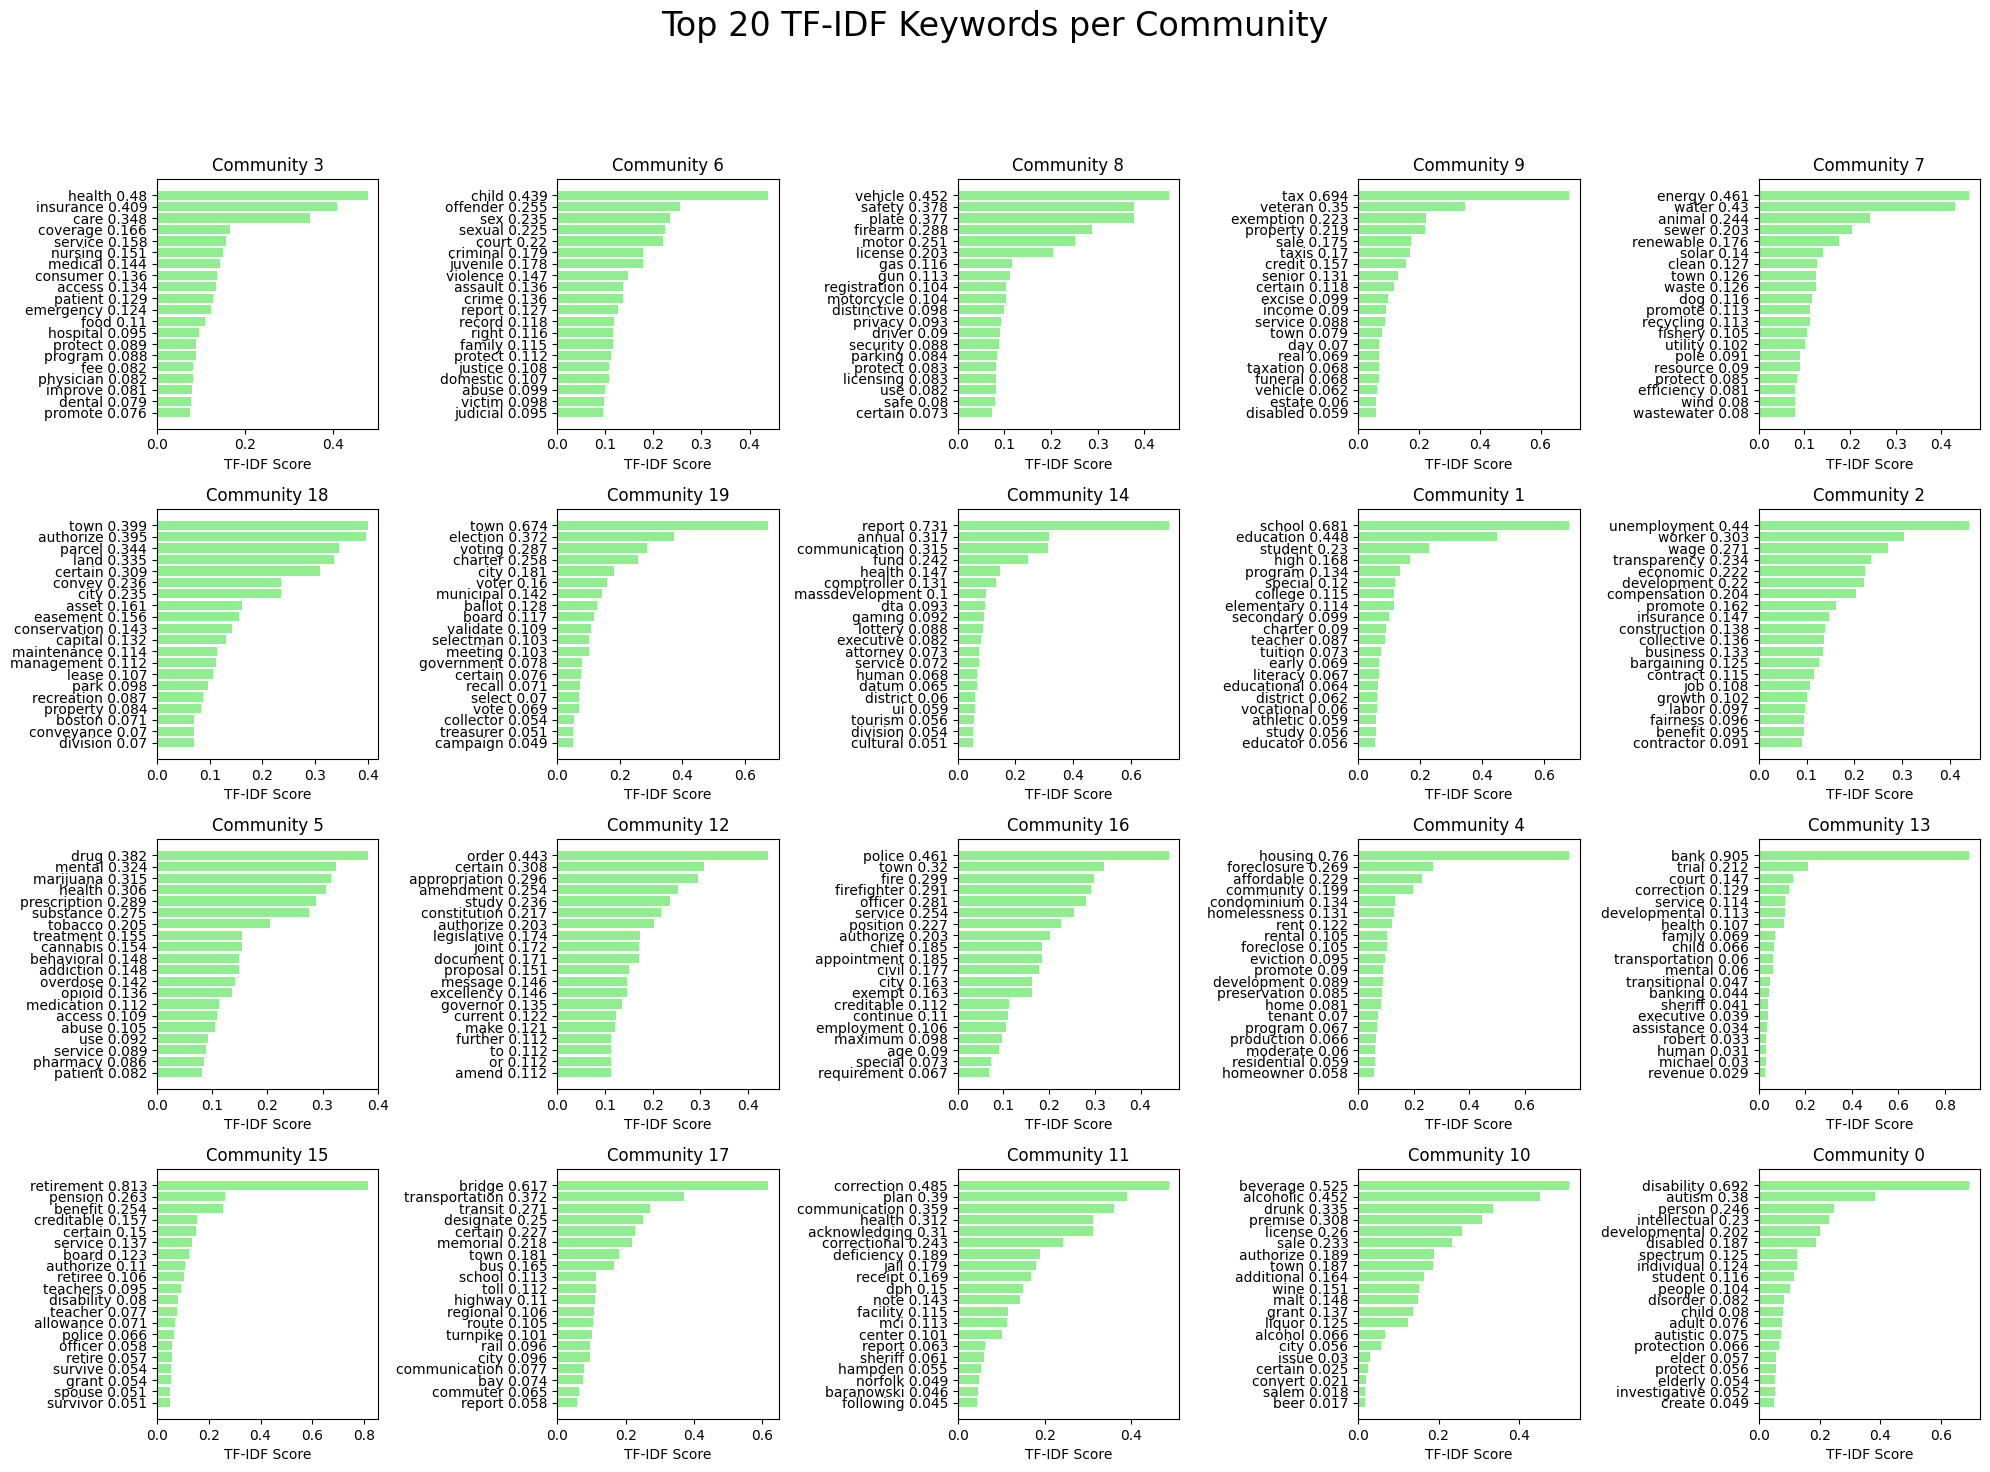

In [105]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Select the top 40 largest communities
top_40_communities = df["community_id"].value_counts().nlargest(40).index.tolist()

# Prepare TF-IDF keywords per community
community_keywords_tfidf = {}

# Join texts per community
texts_by_comm = {
    comm: " ".join(df[df.community_id == comm]["cleaned"])
    for comm in top_40_communities
}

# Fit TF-IDF across communities
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(texts_by_comm.values())
feature_names = tfidf.get_feature_names_out()

# Extract top 40 words by TF-IDF score per community
for i, comm_id in enumerate(top_40_communities):
    row = tfidf_matrix[i].toarray().flatten()
    top_indices = row.argsort()[::-1][:20]
    keywords = [(feature_names[idx], row[idx]) for idx in top_indices]
    community_keywords_tfidf[comm_id] = keywords

# Plot top 40 TF-IDF words per community in a 6x5 grid
fig, axes = plt.subplots(8, 5, figsize=(20, 28), sharey=False)
axes = axes.flatten()
fig.suptitle("Top 20 TF-IDF Keywords per Community", fontsize=24)

for idx, comm_id in enumerate(top_40_communities):
    ax = axes[idx]
    top_words = community_keywords_tfidf[comm_id]
    labels = [f"{w} {round(s, 3)}" for w, s in top_words]
    scores = [s for _, s in top_words]

    ax.barh(labels[::-1], scores[::-1], color='lightgreen')
    ax.set_title(f"Community {comm_id}", fontsize=12)
    ax.set_xlabel("TF-IDF Score")
    ax.set_ylabel("")

# Remove unused subplots if fewer than 40
for j in range(len(top_40_communities), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


In [112]:
community_df = pd.DataFrame(columns=['community_id', 'keywords',  'community_name'])

In [127]:
comm_keywds = pd.DataFrame([
    {"community_id": comm_id, "keywords": [word for word, _ in words]}
    for comm_id, words in community_keywords_tfidf.items()
])
comm_keywds

,community_id,keywords
0,3,"[health, insurance, care, coverage, service, n..."
1,6,"[child, offender, sex, sexual, court, criminal..."
2,8,"[vehicle, safety, plate, firearm, motor, licen..."
3,9,"[tax, veteran, exemption, property, sale, taxi..."
4,7,"[energy, water, animal, sewer, renewable, sola..."
5,18,"[town, authorize, parcel, land, certain, conve..."
6,19,"[town, election, voting, charter, city, voter,..."
7,14,"[report, annual, communication, fund, health, ..."
8,1,"[school, education, student, high, program, sp..."
9,2,"[unemployment, worker, wage, transparency, eco..."


In [134]:
community_data = {
    "community_id": list(range(20)),
    "community_name": [
        "Disability & Developmental Support",
        "Education & Schools",
        "Labor, Employment & Economic Growth",
        "Healthcare & Insurance",
        "Affordable Housing & Homelessness",
        "Substance Use & Mental Health",
        "Child Protection & Criminal Justice",
        "Environmental Resources & Utilities",
        "Transportation & Safety Regulations",
        "Veterans & Tax Policy",
        "Alcohol Licensing & Sales",
        "Correctional Systems & Oversight",
        "Legislative Procedure & Amendments",
        "Human Services & Court Systems",
        "Annual Reporting & Public Agencies",
        "Retirement & Pensions",
        "Emergency Services & Municipal Hiring",
        "Transit, Highways & Memorials",
        "Public Land & City Property Management",
        "Town Elections & Local Governance"
    ]
}

community_data = pd.DataFrame(community_data)
# community_data.join(comm_keywds, on='community_id')

community_df = pd.merge(community_data, comm_keywds, on='community_id', how='inner')
community_df.to_csv('../data/raw/topic_communities.csv', index=False)

In [138]:
df.to_csv('../data/raw/corrected_data.csv', index=False, quotechar='"', quoting=2, encoding='utf-8'     # Ensure that each row ends with a single line brea
    )

In [5]:
df = pd.read_csv('../data/raw/corrected_data.csv')
